In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df=pd.read_csv('telecom_churn.csv')

In [3]:
df.head()

,Churn,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,0,128,1,1,2.7,1,265.1,110,89.0,9.87,10.0
1,0,107,1,1,3.7,1,161.6,123,82.0,9.78,13.7
2,0,137,1,0,0.0,0,243.4,114,52.0,6.06,12.2
3,0,84,0,0,0.0,2,299.4,71,57.0,3.10,6.6
4,0,75,0,0,0.0,3,166.7,113,41.0,7.42,10.1


In [34]:
df.isnull().sum()

Churn              0
AccountWeeks       0
ContractRenewal    0
DataPlan           0
DataUsage          0
CustServCalls      0
DayMins            0
DayCalls           0
MonthlyCharge      0
OverageFee         0
RoamMins           0
dtype: int64

In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Churn            3333 non-null   object 
 1   AccountWeeks     3333 non-null   int64  
 2   ContractRenewal  3333 non-null   int64  
 3   DataPlan         3333 non-null   int64  
 4   DataUsage        3333 non-null   float64
 5   CustServCalls    3333 non-null   int64  
 6   DayMins          3333 non-null   float64
 7   DayCalls         3333 non-null   int64  
 8   MonthlyCharge    3333 non-null   float64
 9   OverageFee       3333 non-null   float64
 10  RoamMins         3333 non-null   float64
dtypes: float64(5), int64(5), object(1)
memory usage: 286.6+ KB


In [5]:
df['Churn'].value_counts()

Churn
0    2850
1     483
Name: count, dtype: int64

In [6]:
#Changing the Churn data from number to categorical for readability
df['Churn'] = df['Churn'].map({1: "Customer has cancelled service", 0:"Customer still using the service"})

In [7]:
df['Churn'].value_counts()

Churn
Customer still using the service    2850
Customer has cancelled service       483
Name: count, dtype: int64

In [8]:
#Split into X and y

X = df.drop('Churn',axis=1)
y = df['Churn']

In [9]:
X

,AccountWeeks,ContractRenewal,DataPlan,DataUsage,CustServCalls,DayMins,DayCalls,MonthlyCharge,OverageFee,RoamMins
0,128,1,1,2.70,1,265.1,110,89.0,9.87,10.0
1,107,1,1,3.70,1,161.6,123,82.0,9.78,13.7
2,137,1,0,0.00,0,243.4,114,52.0,6.06,12.2
3,84,0,0,0.00,2,299.4,71,57.0,3.10,6.6
4,75,0,0,0.00,3,166.7,113,41.0,7.42,10.1
...,...,...,...,...,...,...,...,...,...,...
3328,192,1,1,2.67,2,156.2,77,71.7,10.78,9.9
3329,68,1,0,0.34,3,231.1,57,56.4,7.67,9.6
3330,28,1,0,0.00,2,180.8,109,56.0,14.44,14.1
3331,184,0,0,0.00,2,213.8,105,50.0,7.98,5.0


In [10]:
y

0       Customer still using the service
1       Customer still using the service
2       Customer still using the service
3       Customer still using the service
4       Customer still using the service
                      ...               
3328    Customer still using the service
3329    Customer still using the service
3330    Customer still using the service
3331    Customer still using the service
3332    Customer still using the service
Name: Churn, Length: 3333, dtype: object

In [11]:
from sklearn.model_selection import train_test_split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=101)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

In [14]:
# Penalty Type
penalty = ['l1', 'l2']

# Use logarithmically spaced C values (recommended in official docs)
c = np.logspace(0, 4, 10)

In [15]:
c

array([1.00000000e+00, 2.78255940e+00, 7.74263683e+00, 2.15443469e+01,
       5.99484250e+01, 1.66810054e+02, 4.64158883e+02, 1.29154967e+03,
       3.59381366e+03, 1.00000000e+04])

In [16]:
X_train.shape

(2499, 10)

In [17]:
log_model = LogisticRegression(max_iter=5000)

In [18]:
param_grid = {"C" : c, "penalty" : penalty}

grid_model = GridSearchCV(log_model,param_grid= param_grid, cv=5, verbose=2)

In [19]:
#Train model

grid_model.fit(X_train,y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END ..................................C=1.0, penalty=l1; total time=   0.0s
[CV] END ..................................C=1.0, penalty=l1; total time=   0.0s
[CV] END ..................................C=1.0, penalty=l1; total time=   0.0s
[CV] END ..................................C=1.0, penalty=l1; total time=   0.0s
[CV] END ..................................C=1.0, penalty=l1; total time=   0.0s
[CV] END ..................................C=1.0, penalty=l2; total time=   0.4s
[CV] END ..................................C=1.0, penalty=l2; total time=   0.1s
[CV] END ..................................C=1.0, penalty=l2; total time=   0.2s
[CV] END ..................................C=1.0, penalty=l2; total time=   0.1s
[CV] END ..................................C=1.0, penalty=l2; total time=   0.3s
[CV] END ...................C=2.7825594022071245, penalty=l1; total time=   0.0s
[CV] END ...................C=2.782559402207124

C:\Users\USER\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
50 fits failed out of a total of 100.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
50 fits failed with the following error:
Traceback (most recent call last):
  File "C:\Users\USER\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\USER\anaconda3\Lib\site-packages\sklearn\base.py", line 1365, in wrapper
    return fit_method(estimator, *args, **kwargs)
  File "C:\Users\USER\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py", line 1218, in fit
    solver = _che

,estimator,LogisticRegre...max_iter=5000)
,param_grid,"{'C': array([1.0000...00000000e+04]), 'penalty': ['l1', 'l2']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,5
,verbose,2
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [20]:
#Model best parameter from the grid search
grid_model.best_params_

{'C': np.float64(1.0), 'penalty': 'l2'}

In [21]:
grid_model.best_score_

np.float64(0.8587438877755511)

In [22]:
#Evaluation
from sklearn.metrics import confusion_matrix,classification_report,ConfusionMatrixDisplay, accuracy_score

In [23]:
y_pred = grid_model.predict(X_test)

In [24]:
y_pred

array(['Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer has cancelled service',
       'Customer still using the service',
       'Customer has cancelled service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer has cancelled service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer still using the service',
       'Customer 

In [25]:
#Model Accuracy 

accuracy = accuracy_score(y_test , y_pred)

print(f"Accuracy of the model = {accuracy:.2f}") # Round of to two decimal place

Accuracy of the model = 0.87


In [26]:
#Confusin Matrix

cm = confusion_matrix(y_test,y_pred)
cm

array([[ 19,  86],
       [ 22, 707]])

In [27]:
grid_model.classes_

array(['Customer has cancelled service',
       'Customer still using the service'], dtype=object)

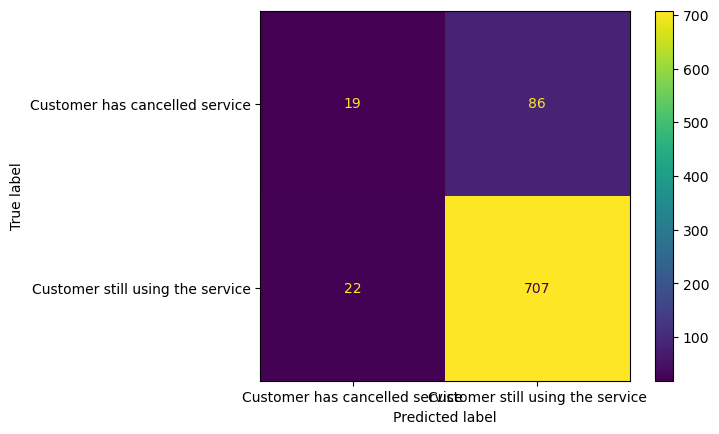

In [28]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=grid_model.classes_)
disp.plot()

plt.show()

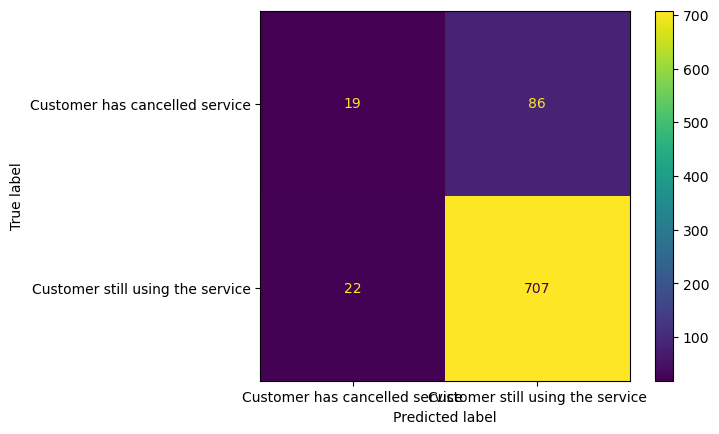

In [29]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=grid_model.classes_)
disp.plot()

plt.show()

In [30]:
#Classification report 
print(classification_report(y_test,y_pred))

                                  precision    recall  f1-score   support

  Customer has cancelled service       0.46      0.18      0.26       105
Customer still using the service       0.89      0.97      0.93       729

                        accuracy                           0.87       834
                       macro avg       0.68      0.58      0.59       834
                    weighted avg       0.84      0.87      0.84       834



In [31]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier , AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

In [32]:
def run_model(model , x_train , x_test , y_train , y_test):
    model.fit(x_train ,y_train)
    y_pred = model.predict(x_test)
    accuracy = accuracy_score(y_test , y_pred)
    print(f"Accuracy of the model {model} : {accuracy:.2f}") #Round of to two decimal places

In [38]:
decision_tree = DecisionTreeClassifier(random_state=101)
RFC = RandomForestClassifier(random_state=101)
knn = KNeighborsClassifier()
Gradient_boost = GradientBoostingClassifier(random_state=101)


In [40]:
for model in [decision_tree , RFC , knn , Gradient_boost]:
    run_model(model , X_train, X_test , y_train , y_test)

Accuracy of the model DecisionTreeClassifier(random_state=101) : 0.89
Accuracy of the model RandomForestClassifier(random_state=101) : 0.93
Accuracy of the model KNeighborsClassifier() : 0.88
Accuracy of the model GradientBoostingClassifier(random_state=101) : 0.94


In [ ]:
##Perform Grid search on Randorm Forest

In [ ]:
gb = GradientBoostingClassifier(random_state=101)

In [ ]:
param_gb={'n_estimators':[20,30,40,50,100],
         'max_depth':list(range(1,11)),
         'max_features':list(range(1,11))}

In [ ]:
grid_gb = GridSearchCV(gb , param_grid=param_gb, cv=5, verbose=2)

In [ ]:
run_model(grid_gb , X_train, X_test , y_train , y_test)

In [ ]:
print("Best Parameters:",grid_gb.best_params_)
print("Best CV Score:",grid_gb.best_score_)

In [ ]:
grid_gb.fit(X_train, y_train)

In [ ]:
import joblib

In [ ]:
joblib.dump(gb.fit(X_train, y_train), "gb.pkl")

In [ ]:
grid_model = joblib.load('gb.pkl')

In [ ]:
grid_model

In [ ]:
grid_model.predict(X_test)